# K-Means: Segmenting Wines by Chemistry

**Family:** Unsupervised learning | **Level:** Beginner | **Dataset:** `wine` | **Runs on:** CPU, about 1 minute(s)

Group rows around centres and learn how to pick k without labels.

## Table of Contents

1. [Learning Objectives](#1.-Learning-Objectives)
2. [Real-World Problem](#2.-Real-World-Problem)
3. [Research Paper](#3.-Research-Paper)
4. [Mathematical Foundation](#4.-Mathematical-Foundation)
5. [Dataset Introduction](#5.-Dataset-Introduction)
6. [Exploratory Data Analysis](#6.-Exploratory-Data-Analysis)
7. [Data Preprocessing](#7.-Data-Preprocessing)
8. [Algorithm Implementation](#8.-Algorithm-Implementation)
9. [Model Training](#9.-Model-Training)
10. [Evaluation](#10.-Evaluation)
11. [Visualization](#11.-Visualization)
12. [Interpretation](#12.-Interpretation)
13. [Experiments and Challenges](#13.-Experiments-and-Challenges)
14. [Research Discussion](#14.-Research-Discussion)
15. [Summary and Further Reading](#15.-Summary-and-Further-Reading)

## 1. Learning Objectives

**After this notebook you will understand:**

- How Lloyd's algorithm alternates assignment and update
- Why k-means needs scaled features
- How to choose k with the elbow and silhouette
- Why results depend on initialisation

**Prerequisites:**

- Distances and vectors
- Standardising features

**Skills you will have afterwards:**

- Pick settings without labels
- Check stability
- Compare with a reference labelling

## 2. Real-World Problem

**Context.** Producers and retailers group products by measurable properties.

**The problem.** Find groups of wines that are similar in 13 chemical measurements, without using the cultivar label.

**Why it matters.** Groups guide blending, pricing and quality control.

**Why machine learning.** Many measurements together define similarity, which no single column does.

**Why this algorithm.** K-means is the standard fast baseline for compact, similar sized groups.

## 3. Research Paper

Entries are grouped by type. Bibliographic details marked *verified* were checked against the publisher record (Crossref) or the arXiv abstract page on 2026-11-17. Entries marked *not verified* come from the author's knowledge and must be checked before citing.

### Least squares quantization in PCM

- **Type:** foundational paper
- **Authors:** Lloyd, S. P.
- **Year and venue:** 1982, IEEE Transactions on Information Theory 28(2):129-137
- **DOI or URL:** https://doi.org/10.1109/TIT.1982.1056489
- **Verification:** Crossref 2026-11-17
- **Research objective:** Find optimal quantisation levels for signals.
- **Methodology:** Alternate between assigning samples to the nearest level and moving levels to the cell mean.
- **Dataset:** Theory, no dataset.
- **Main findings:** The iteration never increases distortion and reaches a local optimum.
- **Limitations:** Local optimum, depends on initialisation, assumes round clusters.

### Silhouettes: A graphical aid to the interpretation and validation of cluster analysis

- **Type:** foundational paper
- **Authors:** Rousseeuw, P. J.
- **Year and venue:** 1987, Journal of Computational and Applied Mathematics 20:53-65
- **DOI or URL:** https://doi.org/10.1016/0377-0427(87)90125-7
- **Verification:** Crossref 2026-11-17
- **Research objective:** Provide a score of how well each point fits its cluster.
- **Methodology:** Compare mean distance within the cluster with mean distance to the nearest other cluster.
- **Dataset:** Small illustrative examples.
- **Main findings:** The silhouette value runs from -1 to 1 and supports choosing the number of clusters.
- **Limitations:** Favours convex clusters and is costly on large data.

**Relationship to this notebook.** Lloyd describes the iterative quantisation procedure now called k-means. Rousseeuw introduces the silhouette used here to compare values of k. This notebook does not reproduce the experimental protocol of any listed paper. It uses a different dataset and split, so numbers are not comparable with the paper.

## 4. Mathematical Foundation

**Objective.** Choose centres $\mu_1..\mu_k$ and assignments to minimise the within cluster sum of squares

$$J = \sum_{i=1}^{n} \lVert x_i - \mu_{c(i)} \rVert^2$$

**Lloyd steps.** Assign each point to its nearest centre, then set each centre to the mean of its points. $J$ never increases, so the loop converges to a local minimum.

**Silhouette.** For a point, $a$ is the mean distance to its own cluster and $b$ the mean distance to the nearest other cluster: $s = (b-a)/\max(a,b)$.

**Assumptions.** Roughly round clusters of similar size, features on one scale. **Limits.** Local minima, sensitive to outliers, k must be given.

## 5. Dataset Introduction

**Wine**, UCI, licence CC BY 4.0, DOI 10.24432/C5PC7J. 178 rows, 13 chemical measurements (alcohol, malic acid, ash, magnesium, phenols, flavanoids, colour intensity, proline and others). Target `cultivar`, three classes. Limits: one region, tiny sample.

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

from ml_lab.data import load_dataset
from ml_lab.evaluation import internal_scores, external_scores
from ml_lab.experiments import ExperimentRecord, save_figure
from ml_lab.utils import set_seed, print_environment
from ml_lab import visualization as viz

NOTEBOOK_ID = "kmeans"
SEED = 42
set_seed(SEED)
viz.apply_style()
print_environment()

bundle = load_dataset("wine")
X_raw = bundle.X
y_true = bundle.y          # evaluation only
print("shape:", X_raw.shape)
display(pd.Series(bundle.describe_source(), name="source").to_frame())

python 3.13.18 | Linux-6.18.44-fc-v595-x86_64-with-glibc2.39
  numpy==2.5.3
  pandas==3.0.5
  scipy==1.18.1
  scikit-learn==1.9.1
  matplotlib==3.11.2
  xgboost==3.4.1
  lightgbm==4.7.0
  catboost==1.2.10
  umap-learn==0.6.0
  torch==2.15.0
  gymnasium==1.4.0
shape: (178, 13)


,source
title,Wine recognition
source,UCI Machine Learning Repository
url,https://archive.ics.uci.edu/dataset/109/wine
license,CC BY 4.0
doi,10.24432/C5PC7J
rows,178
features,13
limits,"Three cultivars from one Italian region, very ..."


## 6. Exploratory Data Analysis

We check size, missing values, label balance and feature relations. The reference labels are used for evaluation only, never for fitting. Compare the ranges of `proline` and `hue` to see why scaling matters.

Rows and columns: (178, 13)
Missing values: 0


,count,mean,std,min,25%,50%,75%,max
alcohol,178.0,13.001,0.812,11.03,12.362,13.050,13.678,14.83
malic_acid,178.0,2.336,1.117,0.74,1.602,1.865,3.082,5.80
ash,178.0,2.367,0.274,1.36,2.210,2.360,2.558,3.23
alcalinity_of_ash,178.0,19.495,3.340,10.60,17.200,19.500,21.500,30.00
magnesium,178.0,99.742,14.282,70.00,88.000,98.000,107.000,162.00
total_phenols,178.0,2.295,0.626,0.98,1.742,2.355,2.800,3.88
flavanoids,178.0,2.029,0.999,0.34,1.205,2.135,2.875,5.08
nonflavanoid_phenols,178.0,0.362,0.124,0.13,0.270,0.340,0.438,0.66
proanthocyanins,178.0,1.591,0.572,0.41,1.250,1.555,1.950,3.58
color_intensity,178.0,5.058,2.318,1.28,3.220,4.690,6.200,13.00


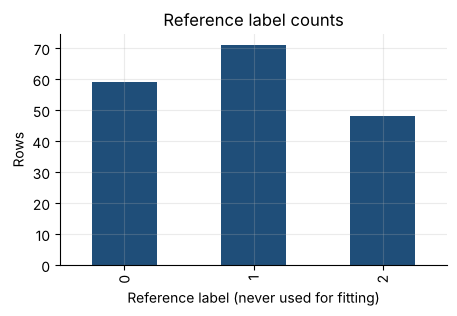

Mean absolute correlation between features: 0.281


In [2]:
print("Rows and columns:", X_raw.shape)
print("Missing values:", int(X_raw.isna().sum().sum()))
display(X_raw.describe().T.head(15).round(3))
fig, ax = plt.subplots(figsize=(5, 3))
pd.Series(y_true).value_counts().sort_index().plot.bar(ax=ax)
ax.set_xlabel("Reference label (never used for fitting)"); ax.set_ylabel("Rows"); ax.set_title("Reference label counts")
plt.show()
corr = X_raw.corr().abs().to_numpy(copy=True)
np.fill_diagonal(corr, 0)
print("Mean absolute correlation between features:", round(float(corr.mean()), 3))

## 7. Data Preprocessing

K-means uses Euclidean distance, so each column is standardised to mean 0 and standard deviation 1. No labels enter this step. There is no train and test split because we describe this dataset, not predict new rows. We check stability by resampling instead.

In [3]:
scaler = StandardScaler().fit(X_raw)
X = scaler.transform(X_raw)
print("scaled mean:", round(float(X.mean()), 3), "| scaled std:", round(float(X.std()), 3))

scaled mean: -0.0 | scaled std: 1.0


## 8. Algorithm Implementation

### 8.1 Concept

Each centre is a prototype. Points join the nearest prototype and prototypes move to the middle of their points until nothing changes.

### 8.2 Python implementation from scratch

We write Lloyd's algorithm in NumPy with random starting centres and keep the best of several starts.

In [4]:
def kmeans_scratch(X, k, n_init=10, iters=100, seed=0):
    rng = np.random.default_rng(seed)
    best = None
    for _ in range(n_init):
        centres = X[rng.choice(len(X), k, replace=False)]
        for _ in range(iters):
            dist = ((X[:, None, :] - centres[None]) ** 2).sum(axis=2)
            labels = dist.argmin(axis=1)
            new = np.array([X[labels == j].mean(axis=0) if (labels == j).any() else centres[j] for j in range(k)])
            if np.allclose(new, centres):
                break
            centres = new
        inertia = ((X - centres[labels]) ** 2).sum()
        if best is None or inertia < best[0]:
            best = (inertia, labels, centres)
    return best

from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score
inertia_mine, labels_mine, _ = kmeans_scratch(X, 3)
ref = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X)
print("inertia scratch:", round(float(inertia_mine), 2), "| sklearn:", round(float(ref.inertia_), 2))
print("agreement of the two labellings (ARI):", round(adjusted_rand_score(labels_mine, ref.labels_), 3))

inertia scratch: 1277.93 | sklearn: 1277.93
agreement of the two labellings (ARI): 1.0


### 8.3 Library implementation

scikit-learn and scipy provide tested implementations.

### 8.4 Important parameters

| Parameter | Meaning |
|---|---|
| `n_clusters` | Number of groups k. |
| `init` | `k-means++` spreads starting centres. |
| `n_init` | Number of restarts, best inertia is kept. |
| `max_iter` | Iteration limit per start. |

## 9. Model Training

We try k from 2 to 8, record inertia and silhouette for each, and choose k by the highest silhouette. The reference label is not used for this choice.

In [5]:
rows = []
for k in range(2, 9):
    km = KMeans(n_clusters=k, n_init=10, random_state=SEED).fit(X)
    s = internal_scores(X, km.labels_)
    rows.append({"k": k, "inertia": km.inertia_, "silhouette": s["Silhouette"], "davies_bouldin": s["Davies_Bouldin"]})
sweep = pd.DataFrame(rows).set_index("k")
display(sweep.round(3))
BEST_K = int(sweep["silhouette"].idxmax())
print("chosen k by silhouette:", BEST_K)
model = KMeans(n_clusters=BEST_K, n_init=10, random_state=SEED).fit(X)
labels = model.labels_

,inertia,silhouette,davies_bouldin
k,,,
2,1658.759,0.259,1.526
3,1277.928,0.285,1.389
4,1175.428,0.260,1.797
5,1109.513,0.202,1.808
6,1046.002,0.237,1.554
7,981.595,0.204,1.661
8,935.201,0.157,1.741


chosen k by silhouette: 3


## 10. Evaluation

Internal scores need no labels: silhouette (higher is better, range -1 to 1), Davies-Bouldin (lower is better) and Calinski-Harabasz (higher is better). External scores (ARI and NMI) compare with a reference label that was never used for fitting. A reference label is not the truth about the data. It is one possible grouping.

In [6]:
METRICS = {**internal_scores(X, labels), **external_scores(y_true, labels)}
rng = np.random.default_rng(SEED)
random_ari = external_scores(y_true, rng.integers(0, BEST_K, len(labels)))["ARI"]
CONFIG = {"k": BEST_K, "n_init": 10, "scaled": True}
EXTRA = {"random_labels_ARI": random_ari, "inertia": float(model.inertia_), "sweep": sweep.round(4).reset_index().to_dict("records")}
print("ARI of random labels (floor):", round(random_ari, 3))

record = ExperimentRecord(notebook=NOTEBOOK_ID, family="unsupervised", algorithm="KMeans", dataset="wine",
                          task="clustering", seed=SEED, config=CONFIG, metrics=METRICS, extra=EXTRA)
print("saved:", record.save())
display(pd.Series(METRICS, name="metric").round(4).to_frame())

ARI of random labels (floor): -0.006
saved: /home/claude/open-python/experiments/results/kmeans.json


,metric
clusters,3.0000
noise_fraction,0.0000
Silhouette,0.2849
Davies_Bouldin,1.3892
Calinski_Harabasz,70.9400
ARI,0.8975
NMI,0.8759


## 11. Visualization

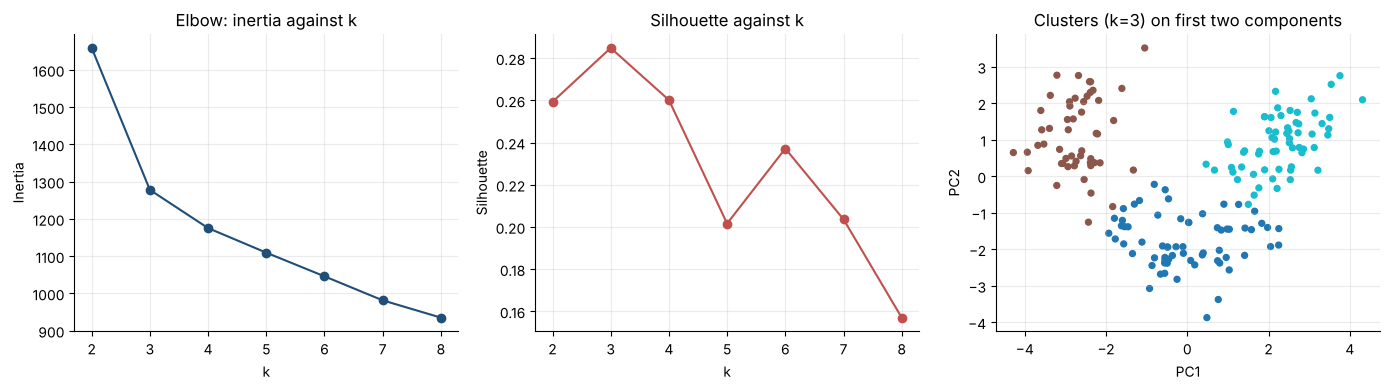

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
sweep["inertia"].plot(marker="o", ax=axes[0]); axes[0].set_title("Elbow: inertia against k"); axes[0].set_ylabel("Inertia")
sweep["silhouette"].plot(marker="o", ax=axes[1], color="C1"); axes[1].set_title("Silhouette against k"); axes[1].set_ylabel("Silhouette")
Z = PCA(2, random_state=SEED).fit_transform(X)
axes[2].scatter(Z[:, 0], Z[:, 1], c=labels, cmap="tab10", s=18); axes[2].set_title(f"Clusters (k={BEST_K}) on first two components")
axes[2].set_xlabel("PC1"); axes[2].set_ylabel("PC2")
plt.tight_layout(); save_figure(fig, NOTEBOOK_ID, "overview"); plt.show()

## 12. Interpretation

Cluster means in original units tell what each group is. Compare the groups with the reference cultivar only as a sanity check.

In [8]:
profile = X_raw.assign(cluster=labels).groupby("cluster").mean().round(2)
display(profile.T.head(8))
display(pd.crosstab(pd.Series(labels, name="cluster"), pd.Series(y_true, name="reference label")))

cluster,0,1,2
alcohol,12.25,13.13,13.68
malic_acid,1.90,3.31,2.00
ash,2.23,2.42,2.47
alcalinity_of_ash,20.06,21.24,17.46
magnesium,92.74,98.67,107.97
total_phenols,2.25,1.68,2.85
flavanoids,2.05,0.82,3.00
nonflavanoid_phenols,0.36,0.45,0.29


reference label,0,1,2
cluster,,,
0,0,65,0
1,0,3,48
2,59,3,0


## 13. Experiments and Challenges

### Experiment 1: Initialisation sensitivity

Run a single random start 30 times and look at the spread of inertia.

In [9]:
inertias = [KMeans(n_clusters=3, init="random", n_init=1, random_state=s).fit(X).inertia_ for s in range(30)]
print("single start inertia: min", round(min(inertias), 2), "max", round(max(inertias), 2), "distinct values", len(set(np.round(inertias, 3))))

single start inertia: min 1277.93 max 1617.37 distinct values 7


### Experiment 2: Scaled versus raw features

Cluster the raw columns and compare with the reference label.

In [10]:
raw = KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X_raw.values)
print("ARI raw features:", round(external_scores(y_true, raw.labels_)["ARI"], 3), "| ARI scaled:", round(external_scores(y_true, KMeans(n_clusters=3, n_init=10, random_state=SEED).fit(X).labels_)["ARI"], 3))

ARI raw features: 0.371 | ARI scaled: 0.897


### Experiment 3: Stability under resampling

Cluster 80 percent samples twice and compare the labellings on the shared rows.

In [11]:
from sklearn.metrics import adjusted_rand_score
rng = np.random.default_rng(SEED)
aris = []
for _ in range(20):
    a = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    b = rng.choice(len(X), int(0.8 * len(X)), replace=False)
    common = np.intersect1d(a, b)
    la = KMeans(BEST_K, n_init=5, random_state=0).fit(X[a]).predict(X[common])
    lb = KMeans(BEST_K, n_init=5, random_state=1).fit(X[b]).predict(X[common])
    aris.append(adjusted_rand_score(la, lb))
print("stability ARI mean", round(float(np.mean(aris)), 3), "std", round(float(np.std(aris, ddof=1)), 3))

stability ARI mean 0.964 std 0.036


### Exercises for learners

1. Repeat with `SEED = 7` and report which numbers move.
2. Change the number of rows by sampling 50 percent and compare the result.
3. Add pure noise columns and watch the internal scores.

## 14. Research Discussion

Lloyd's procedure and Rousseeuw's silhouette work together here. Our sweep shows how the chosen k can differ between the elbow and the silhouette, and the stability experiment shows how much the grouping changes with the sample.

**Dataset and method differences.** The papers above use other data and protocols. We do not claim that our numbers agree or disagree with them. This notebook only shows whether the behaviour they describe appears on our data.

**Possible improvements.** Use gap statistic or stability based selection of k, k-means++ with more restarts, and robust variants for outliers.

**Research limitations.** One dataset and one seed for the headline numbers. 

## 15. Summary and Further Reading

**Key takeaways**

- Scale features before k-means.
- Pick k with several criteria and a stability check.
- Compare with a reference label only as a sanity check.

**Use cases.** Customer segmentation, vector quantisation, initial grouping.

**Limitations.** Round clusters only, k must be set.

**Recommended next notebook.** Hierarchical clustering.

**Further reading.** See `references.md` in this folder.